# Social Media Engagement Analysis: Instagram (Data & Tech Education Account)

**Tools:** Python · pandas · Matplotlib · seaborn · SciPy
**Data:** Real post-level Instagram insights for a data-science education account (119 raw rows, 13 columns). Impressions by traffic source, likes, comments, shares, saves, profile visits, follows, captions, hashtags.

### Business questions
1. How much exposure (impressions) do posts get, and is it evenly spread?
2. Where does that exposure come from: followers (Home), Hashtags or Explore?
3. How engaged is the audience, and *how* do they engage?
4. Which **content types** (topics, hashtags, caption length, calls-to-action) perform best?
5. How well does exposure convert into profile visits and new followers?

## 1. Setup and load raw data

In [1]:
import sys; sys.path.insert(0, "../src")
import warnings; warnings.filterwarnings("ignore")
import pandas as pd, numpy as np
from scipy import stats
import matplotlib.pyplot as plt
import prepare, visualize
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 200)

raw = prepare.load_raw()
print(raw.shape)
raw.head(3)

(119, 13)


,Impressions,From Home,From Hashtags,From Explore,From Other,Saves,Comments,Shares,Likes,Profile Visits,Follows,Caption,Hashtags
0,3920,2586,1028,619,56,98,9,5,162,35,2,Here are some of the most important data visua...,#finance #money #business #investing #investme...
1,5394,2727,1838,1174,78,194,7,14,224,48,10,Here are some of the best data science project...,#healthcare #health #covid #data #datascience ...
2,4021,2085,1188,0,533,41,11,1,131,62,12,Learn how to train a machine learning model an...,#data #datascience #dataanalysis #dataanalytic...


## 2. Data audit and cleaning
Issues found and how they were handled:

| Issue | Finding | Action |
|---|---|---|
| File encoding | Not UTF-8 (Windows-1252 apostrophes, e.g. `\x92`) | Read with `latin-1`, replaced broken characters |
| Column names | Spaces and mixed case | Standardised to `snake_case` |
| Duplicates | Exact duplicate rows | Removed |
| Missing values | Checked every column | None found |
| Source reconciliation | `From Home + Hashtags + Explore + Other` should equal `Impressions` | Checked gap per post; flagged posts where sources exceed impressions |
| Reach metric | Dataset has **Impressions** but no unique-accounts *Reach* column | Impressions used as the exposure metric (stated openly in limitations) |

In [2]:
df, log = prepare.clean(raw)
pd.Series(log, name="cleaning log").to_frame()

,cleaning log
raw_rows,119
exact_duplicates_removed,17
clean_rows,102
missing_values,0
posts_where_sources_exceed_impressions,4


In [3]:
print("Source gap (impressions - sum of sources), summary:")
print(df["source_gap"].describe().round(1))
print(f"\nPosts where sources exceed impressions: {(df['source_gap'] < 0).sum()} of {len(df)}")

Source gap (impressions - sum of sources), summary:
count    102.0
mean      91.9
std      142.2
min     -651.0
25%       45.8
50%      102.0
75%      168.8
max      282.0
Name: source_gap, dtype: float64

Posts where sources exceed impressions: 4 of 102


The source columns do not add up exactly to impressions (the dataset does not document why; likely how Instagram attributes impressions), so **source shares are calculated against the sum of the source columns**, not against impressions.

## 3. Feature engineering
Engagement metrics are rate-based so posts with very different reach can be compared fairly.

| Feature | Definition |
|---|---|
| `interactions` | likes + comments + shares + saves |
| `engagement_rate` | interactions / impressions × 100 |
| `save_rate`, `share_rate` | saves or shares / impressions × 100 |
| `profile_visit_rate` | profile visits / impressions × 100 |
| `follow_rate` | follows / profile visits × 100 |
| `*_pct` | share of impressions by source (Home, Hashtags, Explore, Other) |
| `hashtag_count`, `caption_length` | extracted from text |
| `has_link_in_bio` | caption contains a "link in bio" call-to-action |
| `topic` | content theme assigned by transparent keyword rules (`src/prepare.py`) |
| `viral_flag` | top 10% of posts by impressions |

In [4]:
df[["post_id","impressions","interactions","engagement_rate","profile_visit_rate","hashtag_count","caption_length","topic"]].head()

,post_id,impressions,interactions,engagement_rate,profile_visit_rate,hashtag_count,caption_length,topic
0,1,3920,274,6.989796,0.892857,22,112,Data Viz & Statistics
1,2,5394,439,8.138673,0.889878,18,187,Project Ideas & Portfolio
2,3,4021,184,4.575976,1.541905,18,117,Machine Learning & Deep Learning
3,4,4528,402,8.878092,0.507951,11,202,Python Tutorials & Scripts
4,5,2518,228,9.054805,0.317712,29,178,Data Viz & Statistics


In [5]:
df.to_csv("../data/processed/instagram_clean.csv", index=False)
df["topic"].value_counts().to_frame("posts")

,posts
topic,
Project Ideas & Portfolio,28
Machine Learning & Deep Learning,23
Career & Learning Resources,21
Python Tutorials & Scripts,11
Industry Use Cases,10
Data Viz & Statistics,9


## 4. Headline KPIs

In [6]:
kpi = pd.Series({
    "Posts analysed": len(df),
    "Total impressions": df["impressions"].sum(),
    "Median impressions / post": df["impressions"].median(),
    "Mean impressions / post": round(df["impressions"].mean()),
    "Best post (impressions)": df["impressions"].max(),
    "Median engagement rate (%)": round(df["engagement_rate"].median(), 2),
    "Total profile visits": df["profile_visits"].sum(),
    "Total follows": df["follows"].sum(),
})
kpi.to_frame("value")

,value
Posts analysed,102.00
Total impressions,603866.00
Median impressions / post,4343.50
Mean impressions / post,5920.00
Best post (impressions),36919.00
Median engagement rate (%),6.22
Total profile visits,5576.00
Total follows,2328.00


## 5. Reach and impressions

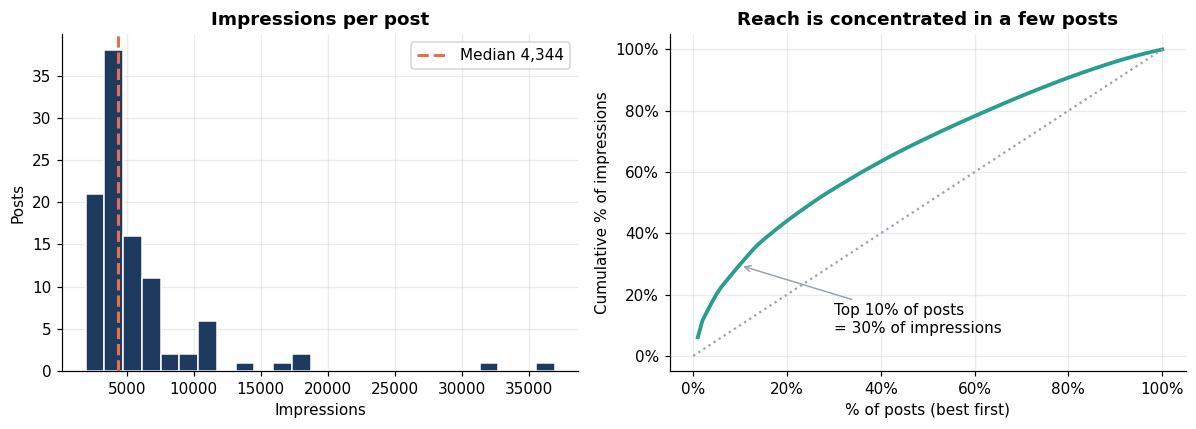

In [7]:
visualize.impressions_distribution(df); plt.show()

In [8]:
top10 = df.nlargest(10, "impressions")
print(f"Top 10 posts (~10% of posts) generate {top10['impressions'].sum() / df['impressions'].sum():.1%} of all impressions")
print(f"Median post: {df['impressions'].median():,.0f}  |  mean: {df['impressions'].mean():,.0f}  |  max: {df['impressions'].max():,.0f}")

Top 10 posts (~10% of posts) generate 29.5% of all impressions
Median post: 4,344  |  mean: 5,920  |  max: 36,919


**Finding.** Reach is highly skewed: the median post gets about **4.3K impressions**, but the **top 10 posts (about 10% of the feed) generate ~30% of all impressions**, with a best post near 37K. Average performance is therefore a poor guide, and the strategy question becomes *what makes a post break out?*

### Where impressions come from

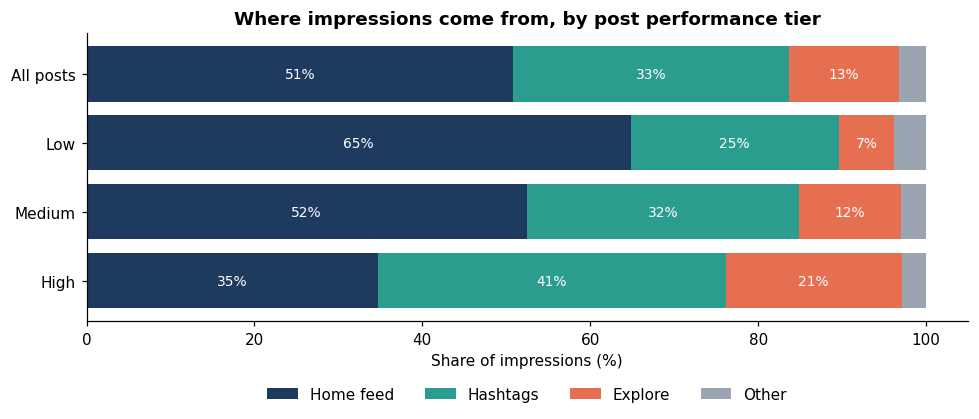

In [9]:
visualize.traffic_sources(df); plt.show()

In [10]:
cols = ["from_home_pct","from_hashtags_pct","from_explore_pct","from_other_pct"]
print("Average source mix (%):"); print(df[cols].mean().round(1).to_string())
print("\nTop-10% posts vs everything else (median):")
df.groupby("viral_flag")[cols + ["follows","profile_visits"]].median().round(1).rename(index={False: "Other posts", True: "Top 10%"})

Average source mix (%):
from_home_pct        50.8
from_hashtags_pct    32.8
from_explore_pct     13.1
from_other_pct        3.2

Top-10% posts vs everything else (median):


,from_home_pct,from_hashtags_pct,from_explore_pct,from_other_pct,follows,profile_visits
viral_flag,,,,,,
Other posts,52.8,31.0,7.6,1.6,8.0,22.0
Top 10%,29.4,27.5,39.2,1.8,94.0,155.0


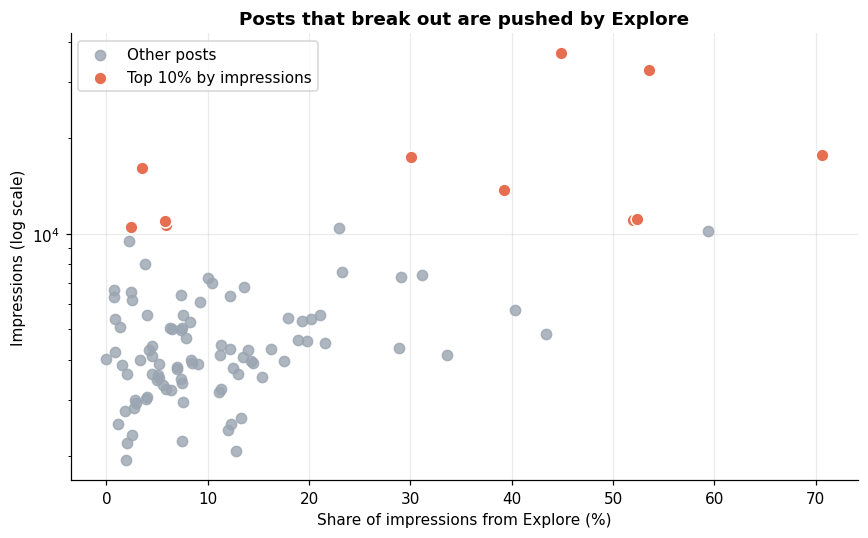

In [11]:
visualize.explore_vs_impressions(df); plt.show()

**Finding.** On average, about **51% of impressions come from the Home feed (existing followers), 33% from hashtags, 13% from Explore**. The top-performing posts look different: they draw a median **~39% of impressions from Explore (vs ~8% for other posts)** and far less from the Home feed. Breakout reach comes from Instagram recommending the post to non-followers, and those posts also bring in many more new followers (median **94 follows vs 8**).

## 6. Engagement

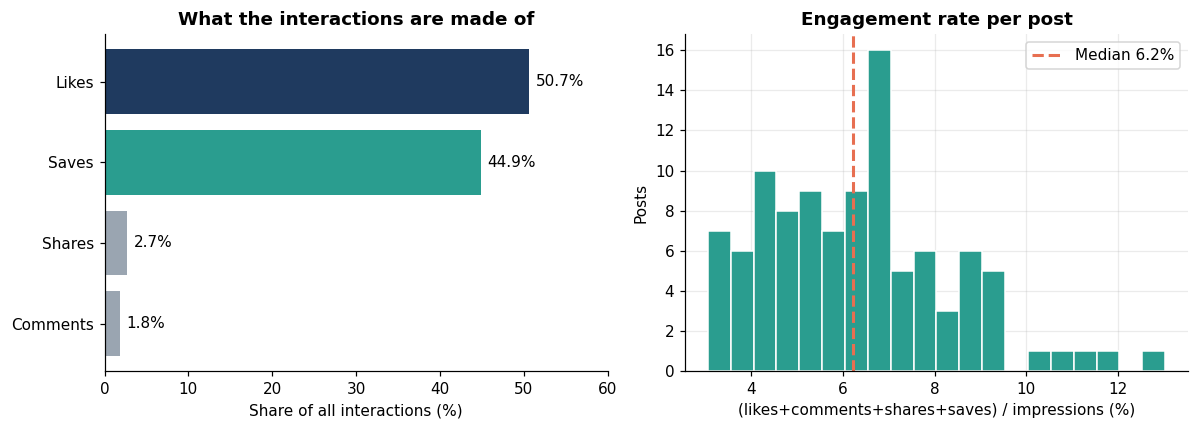

In [12]:
visualize.engagement_overview(df); plt.show()

In [13]:
mix = df[["likes","saves","shares","comments"]].sum(); print((mix / mix.sum() * 100).round(1).to_string())
print(f"\nMedian engagement rate: {df['engagement_rate'].median():.2f}%   (IQR {df['engagement_rate'].quantile(.25):.1f}% - {df['engagement_rate'].quantile(.75):.1f}%)")
r, p = stats.spearmanr(df["impressions"], df["engagement_rate"])
print(f"Impressions vs engagement rate: Spearman rho={r:.2f}, p={p:.3f}")

likes       50.7
saves       44.9
shares       2.7
comments     1.8

Median engagement rate: 6.22%   (IQR 4.8% - 7.5%)
Impressions vs engagement rate: Spearman rho=-0.17, p=0.083


**Finding.** Median engagement rate is **~6.2%**. Interactions are dominated by **likes (51%) and saves (45%)**; shares (2.7%) and comments (1.8%) are tiny. This is a *"save-for-later"* audience: educational content people bookmark rather than discuss. Engagement *rate* drifts down slightly as impressions grow (rho = -0.17, p = 0.08, not statistically significant), which is normal as posts reach colder, non-follower audiences.

## 7. Content-level analysis

### 7.1 Topic

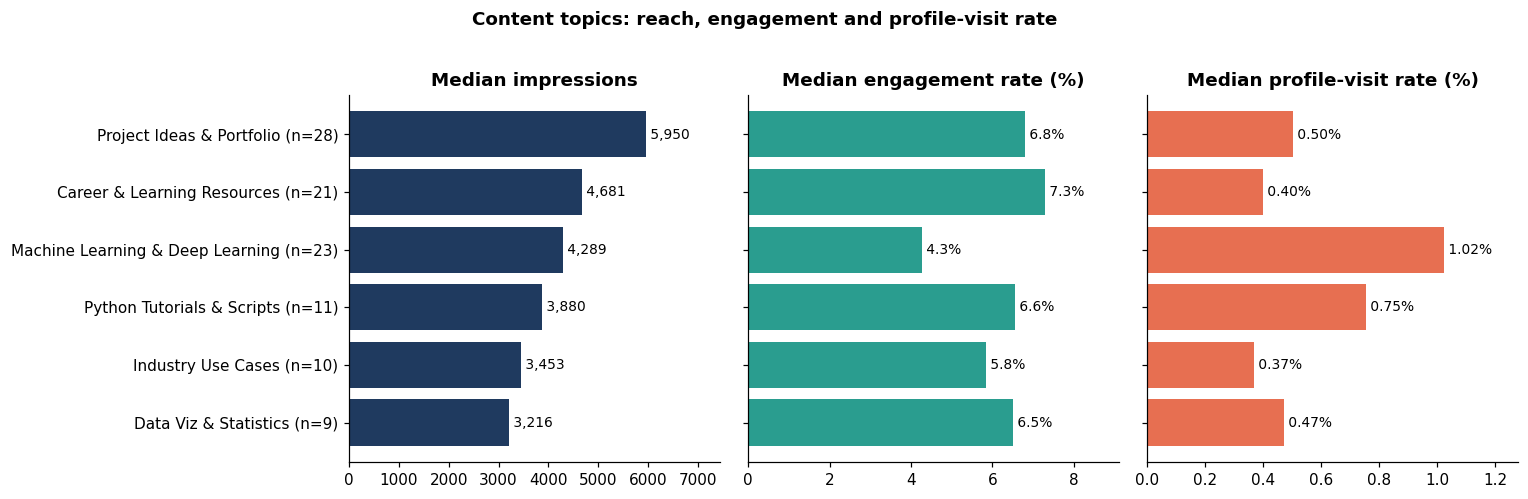

In [14]:
visualize.topic_performance(df); plt.show()

In [15]:
g = df.groupby("topic").agg(posts=("post_id","count"), median_impressions=("impressions","median"),
        median_eng_rate=("engagement_rate","median"), median_save_rate=("save_rate","median"),
        median_profile_visit_rate=("profile_visit_rate","median"), median_follows=("follows","median")).round(2)
display(g.sort_values("median_impressions", ascending=False))
for m in ["impressions","engagement_rate","profile_visit_rate"]:
    H, p = stats.kruskal(*[x[m].values for _, x in df.groupby("topic")])
    print(f"Kruskal-Wallis across topics on {m}: H={H:.1f}, p={p:.5f}")

,posts,median_impressions,median_eng_rate,median_save_rate,median_profile_visit_rate,median_follows
topic,,,,,,
Project Ideas & Portfolio,28,5949.5,6.79,2.79,0.50,10.0
Career & Learning Resources,21,4681.0,7.28,3.35,0.40,8.0
Machine Learning & Deep Learning,23,4289.0,4.28,1.14,1.02,12.0
Python Tutorials & Scripts,11,3880.0,6.56,2.37,0.75,10.0
Industry Use Cases,10,3453.0,5.83,1.96,0.37,2.0
Data Viz & Statistics,9,3216.0,6.49,2.92,0.47,2.0


Kruskal-Wallis across topics on impressions: H=24.5, p=0.00017
Kruskal-Wallis across topics on engagement_rate: H=31.7, p=0.00001
Kruskal-Wallis across topics on profile_visit_rate: H=30.5, p=0.00001


**Finding.** Topic matters (all three Kruskal-Wallis tests have p < 0.001):

- **Project Ideas & Portfolio** posts reach the most people (median ~5.9K impressions).
- **Career & Learning Resources** posts earn the highest engagement rate (**7.3%**) and save rate.
- **Machine Learning & Deep Learning** posts have the *lowest* engagement rate (4.3%) but the **highest profile-visit rate (1.0%)**: they attract curious visitors rather than savers.
- **Data Viz & Statistics** and **Industry Use Cases** are the weakest on reach (small samples, n = 9 and 10, so treat as directional).

### 7.2 Hashtags and caption length

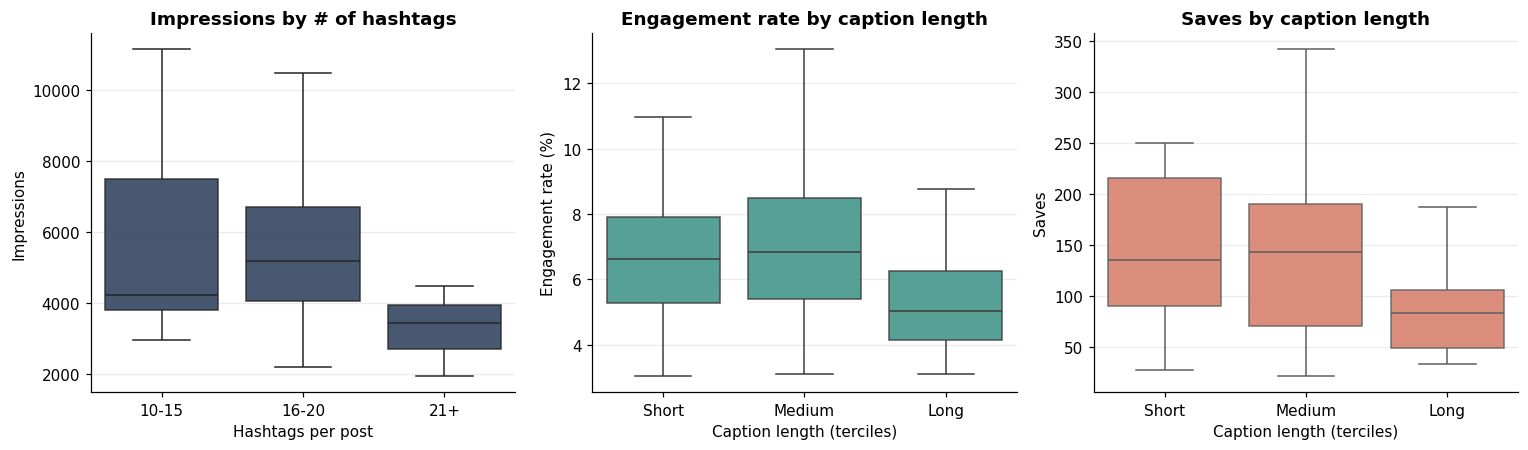

In [16]:
visualize.hashtag_and_caption(df); plt.show()

In [17]:
for x, y in [("hashtag_count","impressions"),("hashtag_count","from_hashtags"),("caption_length","impressions"),
             ("caption_length","engagement_rate"),("caption_length","saves")]:
    r, p = stats.spearmanr(df[x], df[y]); print(f"{x:>15} vs {y:<16} rho={r:+.2f}  p={p:.3f}")
b = pd.cut(df["hashtag_count"], [0,15,20,40], labels=["10-15","16-20","21+"])
df.groupby(b, observed=True)["impressions"].agg(["count","median"]).rename(columns={"median":"median_impressions"})

  hashtag_count vs impressions      rho=-0.45  p=0.000
  hashtag_count vs from_hashtags    rho=-0.31  p=0.002
 caption_length vs impressions      rho=+0.00  p=0.997
 caption_length vs engagement_rate  rho=-0.25  p=0.012
 caption_length vs saves            rho=-0.23  p=0.020


,count,median_impressions
hashtag_count,,
10-15,18,4224.0
16-20,60,5172.5
21+,24,3434.0


**Finding.**
- **More hashtags did not mean more reach.** Hashtag count is *negatively* related to impressions (rho = -0.45, p < 0.001). Posts with 21+ hashtags had the lowest median impressions (~3.4K) vs ~5.2K for 16-20. This is an association on one account, not proof that hashtags hurt, but it clearly argues against hashtag stuffing.
- **Caption length does not drive reach** (rho = 0.00), but **shorter captions have higher engagement and save rates** (rho = -0.25 and -0.23, p < 0.05).

### 7.3 'Link in bio' call-to-action

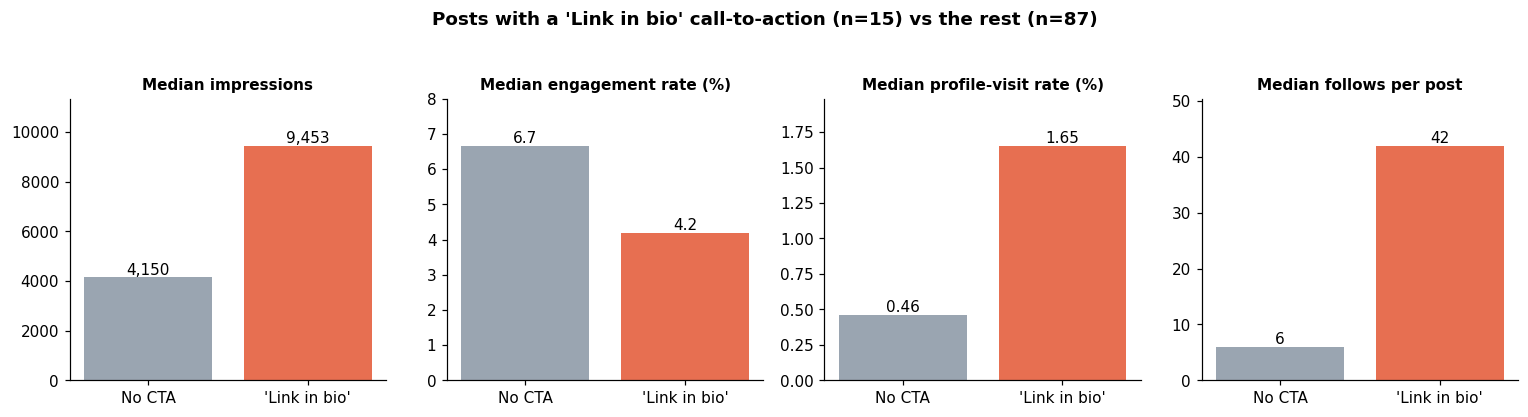

In [18]:
visualize.link_in_bio(df); plt.show()

In [19]:
a, b = df[df["has_link_in_bio"]], df[~df["has_link_in_bio"]]
rows = []
for m in ["impressions","engagement_rate","profile_visit_rate","follows"]:
    rows.append({"metric": m, "link_in_bio_median": a[m].median(), "other_median": b[m].median(),
                 "mann_whitney_p": stats.mannwhitneyu(a[m], b[m]).pvalue})
pd.DataFrame(rows).round(4)

,metric,link_in_bio_median,other_median,mann_whitney_p
0,impressions,9453.000,4150.0000,0.0005
1,engagement_rate,4.198,6.6684,0.0000
2,profile_visit_rate,1.655,0.4638,0.0000
3,follows,42.000,6.0000,0.0000


**Finding.** The 15 posts with a "link in bio" CTA reach **over 2x more people** (median 9.5K vs 4.2K impressions) and drive **~3.5x the profile-visit rate** (1.65% vs 0.46%) and far more follows (**42 vs 6**), but their engagement *rate* is lower (4.2% vs 6.7%). CTA posts convert curiosity into profile traffic; non-CTA posts get more bookmarking. (CTA posts are also promotional/project posts, so this is not a pure test of the CTA itself.)

## 8. Conversion funnel

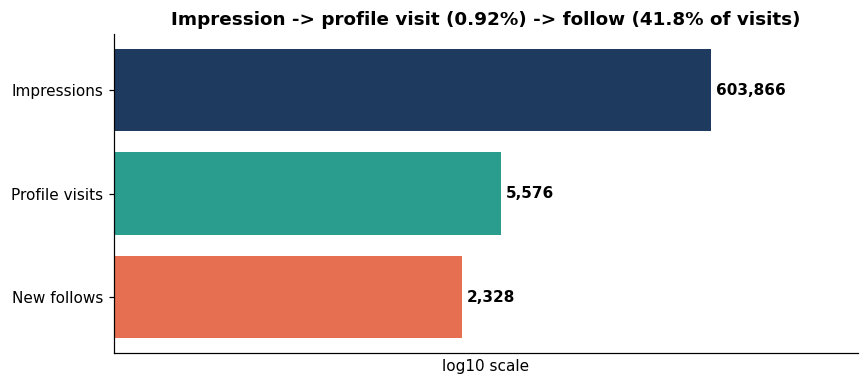

In [20]:
visualize.funnel(df); plt.show()

**Finding.** Out of ~604K impressions, ~5.6K led to a profile visit (**0.92%**) and ~2.3K to new follows. A **41.8% visit-to-follow rate** means the profile itself converts well. The leak is at the top: very few viewers click through to the profile.

## 9. What moves together? (correlations)

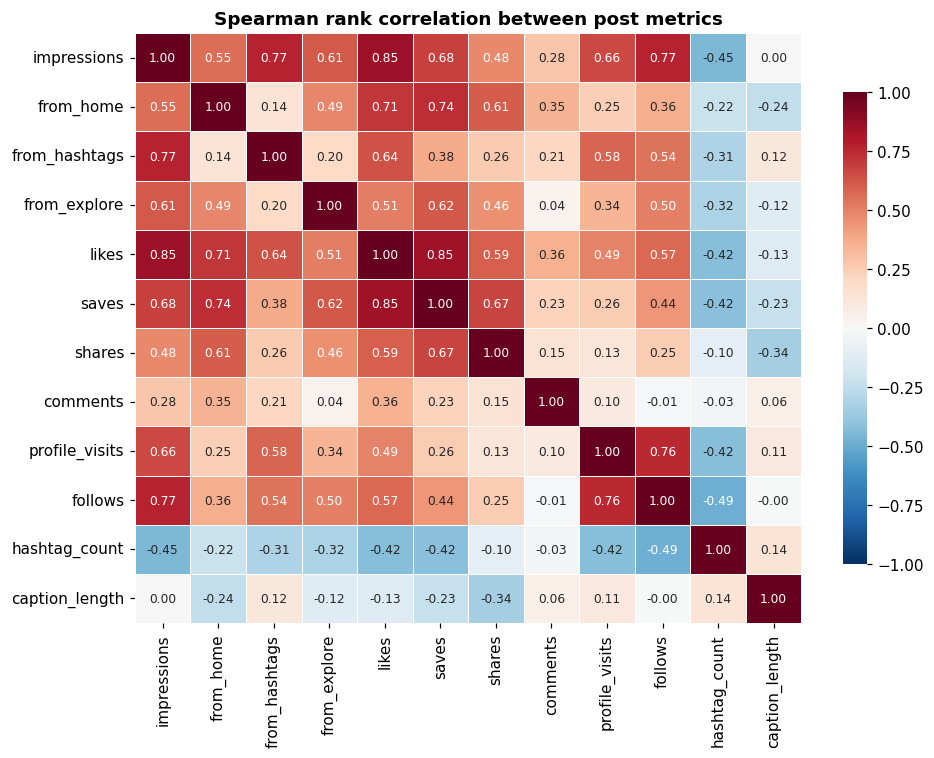

In [21]:
visualize.correlation_heatmap(df); plt.show()

Reach (impressions) is most strongly tied to **likes (rho 0.85)**, **follows (0.77)** and **hashtag-sourced traffic (0.77)**, then **saves (0.68)** and **profile visits (0.66)**; comments are the weakest signal (0.28). Saves track reach closely, supporting the idea that save-worthy content is what Instagram amplifies.

## 10. Key findings and recommendations

| # | Insight (evidence) | Recommendation |
|---|---|---|
| 1 | Top 10 posts (~10%) = ~30% of impressions | Study and **repeat the formats of breakout posts**; do not manage to the average |
| 2 | Top posts get ~39% of impressions from Explore vs ~8% for others, and bring ~12x the follows | **Design for non-followers**: clear hook, standalone value, save-worthy structure |
| 3 | Saves = 45% of interactions; saves correlate with reach (rho 0.68) | Make **carousels / checklists / cheat-sheets** people bookmark; add a "save this" prompt |
| 4 | 21+ hashtags had the lowest median impressions; correlation -0.45 | **Cap at ~16-20 relevant hashtags**; test lower counts |
| 5 | Shorter captions have higher engagement and saves | Keep captions tight; move depth into the slides/visual |
| 6 | "Link in bio" posts: 2x reach, 3.5x profile-visit rate, 7x follows, lower engagement rate | Use CTAs on **growth-goal posts**; keep non-CTA posts for community engagement |
| 7 | Project-idea and career-resource posts lead on reach and engagement | Make them the **content backbone**; use ML-theory posts for profile traffic |
| 8 | Only 0.92% of impressions become profile visits | Test stronger **profile hooks** and bio-link CTAs on high-reach posts |

## 11. Limitations (read before quoting numbers)
- **One account, 102 unique posts**: results describe this account, not Instagram generally. Small topic groups (n < 12) are directional.
- **No dates in the dataset**, so time-of-day, day-of-week and trend analysis were not possible.
- **No unique-accounts "Reach" column**: *impressions* are used as the exposure measure.
- **Correlation is not causation**: hashtag, caption and CTA effects are associations; posts differ in many ways.
- **Topics are keyword-assigned** (rules in `src/prepare.py`); borderline captions could reasonably be labelled differently.
- Source columns do not sum exactly to impressions (see section 2).